# Example of the aitlas toolbox in the context of semantic segmentation

This notebook showcases a machine learning example for the AeroRIT dataset, using the RGB image of the dataset.

## Import the required packages

In [ ]:
from aitlas.datasets import AeroRITDataset
from aitlas.utils import image_loader
from aitlas.models import DeepLabV3
from aitlas.transforms import MinMaxNormTranspose, ResizeToTensor

## Visualize images and masks

Total number of patches: 105


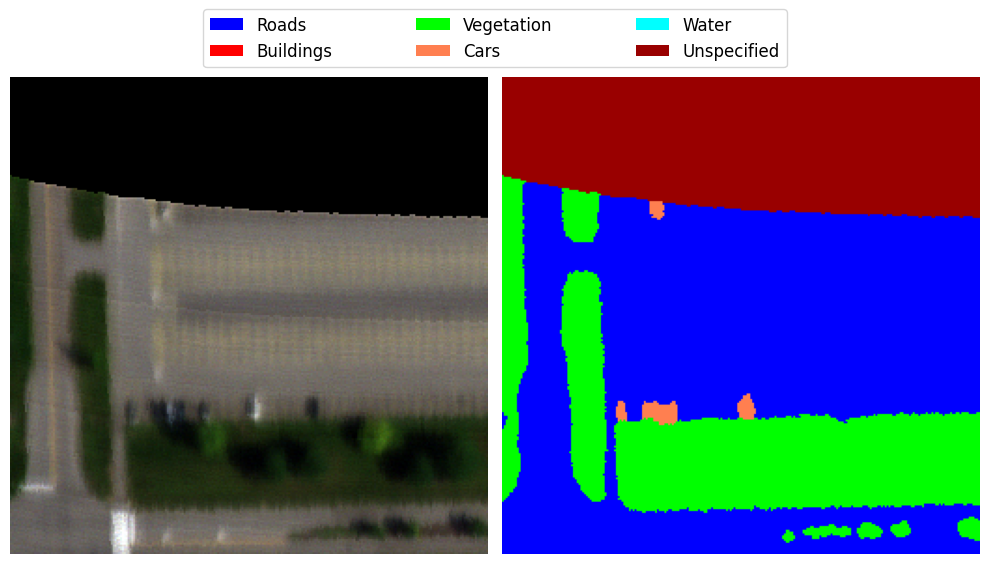

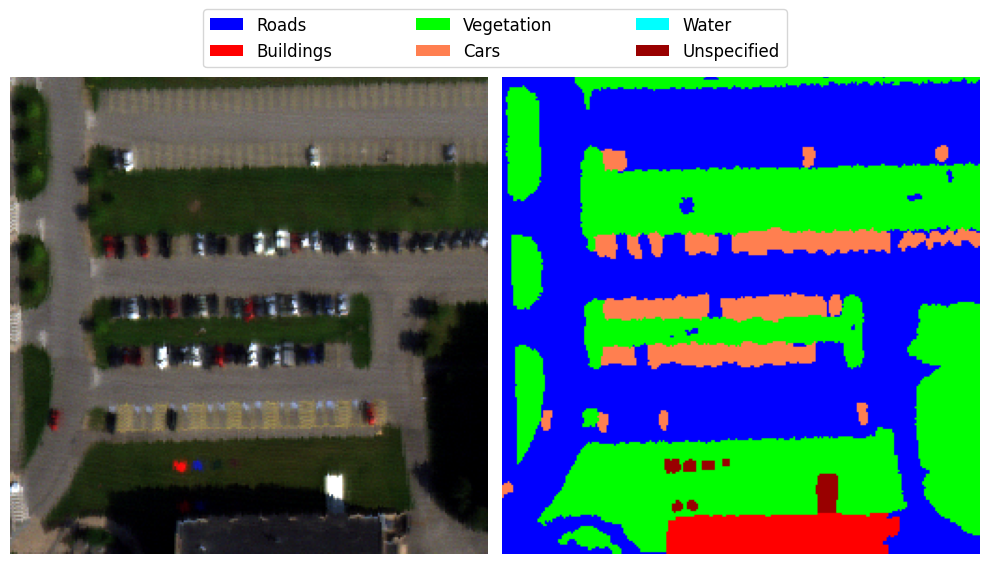

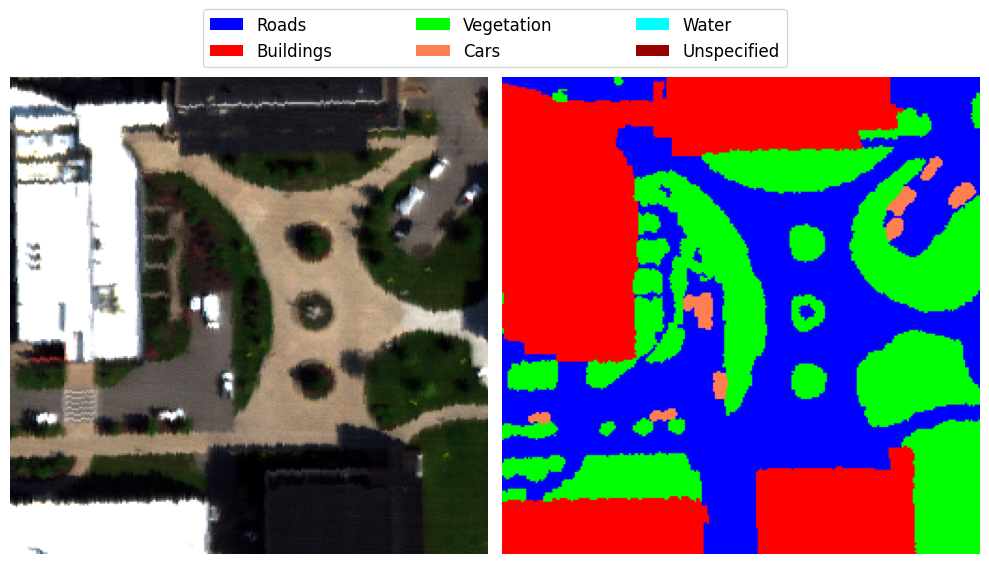

In [5]:
dataset_config = {
    "data_dir": "/home/dragik/data/FAIR_EO/AeroRIT"
}
dataset = AeroRITDataset(dataset_config)

print(f"Total number of patches: {len(dataset)}")
dataset.show_image(20);
dataset.show_image(50);
dataset.show_image(65);

In [26]:
dataset.data_distribution_table()

,Number of pixels
Roads,1809340.0
Buildings,854200.0
Vegetation,2946749.0
Cars,126759.0
Water,118513.0
Unspecified,1025719.0


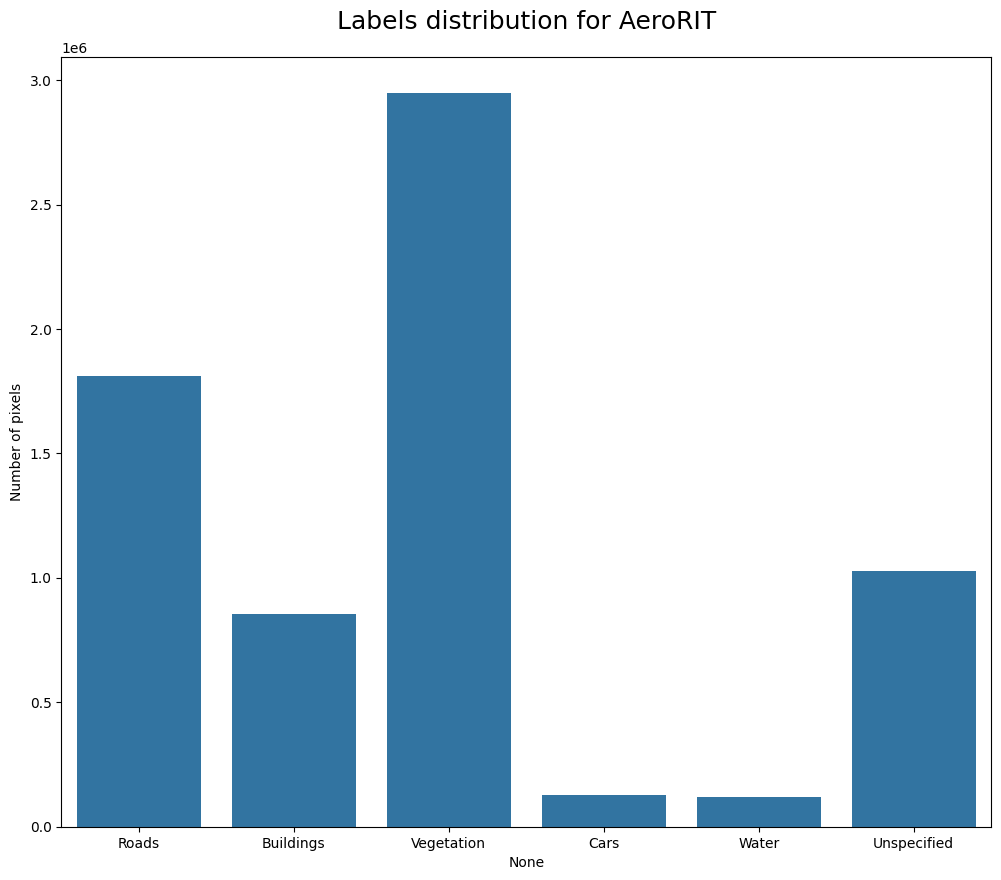

In [27]:
dataset.data_distribution_barchart();

## Load training data

In [6]:
train_dataset_config = {
    "batch_size": 8,
    "shuffle": True,
    "num_workers": 4,
    "data_dir": "/home/dragik/data/FAIR_EO/AeroRIT",
    "mode": "train",
    "transforms": ["aitlas.transforms.MinMaxNormTranspose","aitlas.transforms.ResizeToTensor"], 
    "target_transforms": ["aitlas.transforms.Transpose","aitlas.transforms.ResizePerChannelToTensor"] 
}
train_dataset = AeroRITDataset(train_dataset_config)
len(train_dataset)

84

## Create the model

In [10]:
epochs = 20
model_directory = "/home/dragik/data/FAIR_EO/experiments/AeroRIT"
model_config = {
    "num_classes": 6, 
    "learning_rate": 0.0001,
    "pretrained": True, 
    "threshold": 0.5,
    "metrics": ["iou"]
}

model = DeepLabV3(model_config)
model.prepare()

## Start the training

In [11]:
model.train_model(
    train_dataset=train_dataset,
    epochs=epochs,
    model_directory=model_directory,
    run_id='1'
);

2025-09-04 11:19:56,993 INFO Starting training.
training: 100%|██████████| 11/11 [00:21<00:00,  1.93s/it]
2025-09-04 11:20:18,261 INFO epoch: 1, time: 21, loss:  0.70759
testing on train set: 100%|██████████| 11/11 [00:21<00:00,  1.91s/it]
2025-09-04 11:20:41,273 INFO IOU:0.3446755107253048, IOU mean:0.34317074209595644, IOU per Class:[0.32841595 0.39899171 0.55280935 0.04357581 0.04235897 0.69287266]
training: 100%|██████████| 11/11 [00:22<00:00,  2.01s/it]
2025-09-04 11:21:03,371 INFO epoch: 2, time: 22, loss:  0.65164
testing on train set: 100%|██████████| 11/11 [00:20<00:00,  1.89s/it]
2025-09-04 11:21:24,136 INFO IOU:0.48737827296328523, IOU mean:0.4409501506942588, IOU per Class:[0.43328462 0.51670534 0.68435431 0.07295632 0.22884024 0.70956007]
training: 100%|██████████| 11/11 [00:20<00:00,  1.91s/it]
2025-09-04 11:21:45,134 INFO epoch: 3, time: 21, loss:  0.60648
testing on train set: 100%|██████████| 11/11 [00:20<00:00,  1.90s/it]
2025-09-04 11:22:06,099 INFO IOU:0.53359754560

## Evaluate the model

In [12]:
test_dataset_config = {
    "batch_size": 4,
    "shuffle": False,
    "num_workers": 4,
    "data_dir": "/home/dragik/data/FAIR_EO/AeroRIT",
    "mode": "val",
    "transforms": ["aitlas.transforms.MinMaxNormTranspose","aitlas.transforms.ResizeToTensor"], 
    "target_transforms": ["aitlas.transforms.Transpose","aitlas.transforms.ResizePerChannelToTensor"] 
}

test_dataset = AeroRITDataset(test_dataset_config)
print(len(test_dataset))

model = DeepLabV3(model_config)
model.prepare()
model.running_metrics.reset()
model_path = "/home/dragik/data/FAIR_EO/experiments/AeroRIT/checkpoint.pth.tar"
model.evaluate(dataset=test_dataset, model_path=model_path)
model.running_metrics.get_scores(model.metrics)

10


2025-09-04 11:36:16,056 INFO Loading checkpoint /home/dragik/data/FAIR_EO/experiments/AeroRIT/checkpoint.pth.tar
2025-09-04 11:36:17,672 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/experiments/AeroRIT/checkpoint.pth.tar at epoch 21
testing on test set: 100%|██████████| 3/3 [00:03<00:00,  1.13s/it]


[{'IOU': 0.023621931716478133,
  'IOU mean': 0.014029149397285461,
  'IOU per Class': array([0.01486467, 0.00768438, 0.04111791, 0.        , 0.        ,
         0.02050794])}]

## Predictions

2025-09-04 11:37:19,456 INFO Loading checkpoint /home/dragik/data/FAIR_EO/experiments/AeroRIT/checkpoint.pth.tar
2025-09-04 11:37:19,762 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/experiments/AeroRIT/checkpoint.pth.tar at epoch 21


11


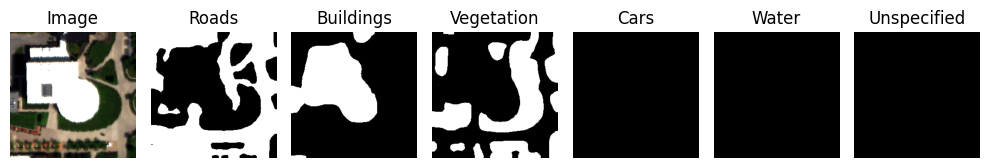

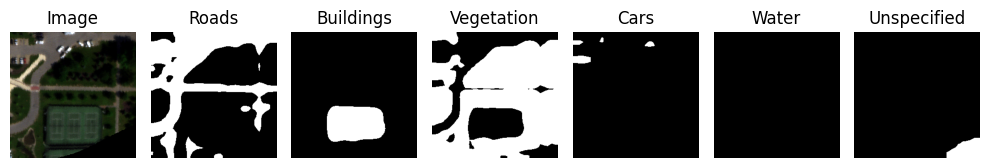

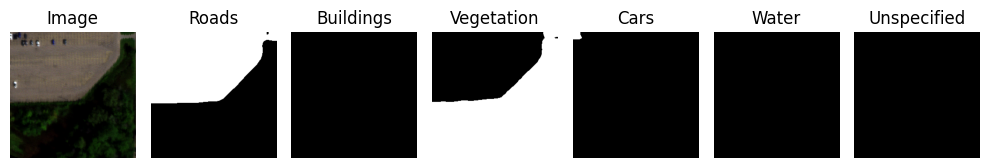

In [ ]:
model_path = "/home/dragik/data/FAIR_EO/experiments/AeroRIT/checkpoint.pth.tar"
labels = ["Roads","Buildings","Vegetation","Cars","Water","Unspecified"]
transform = ResizeToTensor()
model.load_model(model_path)

test_dataset_config = {
    "data_dir": "/home/dragik/data/FAIR_EO/AeroRIT",
    "mode": "test",
}
test_dataset = AeroRITDataset(test_dataset_config)
print(len(test_dataset))

image = test_dataset[0][0]
fig = model.predict_masks(image, labels, transform)

image = test_dataset[5][0]
fig = model.predict_masks(image, labels, transform)

image = test_dataset[10][0]
fig = model.predict_masks(image, labels, transform)